# 01 - Exploratory Data Analysis

Training data: Kaggle **Google Play Store Reviews** (`prakharrathi25`, file `User Reviews.csv`)
and/or **google-play-store-apps** user reviews (`lava18`, file `user_reviews.csv`).

Drop both CSVs into `data/raw/`, then run this notebook top to bottom.
It profiles the data, cleans it, and writes `data/processed/reviews_clean.csv`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src import DATA_RAW, DATA_PROCESSED, set_seed
set_seed()
sns.set_theme()
pd.set_option('display.max_colwidth', 80)

## 1. Load raw data
Auto-detect whichever Kaggle file is present and normalise column names
(`prakharrathi25` uses `App`/`Translated Review`, `lava18` uses `content`).

In [2]:
def load_raw():
    for fname, txtcol, scorecol in [
        ('User Reviews.csv', 'Translated Review', 'Sentiment'),
        ('reviews.csv', 'content', 'score')]:
        path = os.path.join(DATA_RAW, fname)
        if os.path.exists(path):
            df = pd.read_csv(path)
            df = df.rename(columns={txtcol: 'review'})
            if scorecol in df.columns:
                df = df.rename(columns={scorecol: 'score'})
            print(f'loaded {fname}')
            return df
    raise FileNotFoundError('No training CSV found in data/raw')

df = load_raw()
df.head()

loaded reviews.csv


,reviewId,userName,userImage,review,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,sortOrder,appId
0,gp:AOqpTOEhZuqSqqWnaKRgv-9ABYdajFUB0WugPGh-SG-fgH355YH_t7J2q4xYo6ZzN3Mc7iSrr...,Eric Tie,https://play-lh.googleusercontent.com/a-/AOh14GiGET2XHTvsSEsA07ZBPu2s1E6fOXd...,I cannot open the app anymore,1,0,5.4.0.6,2020-10-27 21:24:41,NaN,NaN,newest,com.anydo
1,gp:AOqpTOH0WP4IQKBZ2LrdNmFy_YmpPCVrV3diEU9KGm3fAX6VG0NAZCudCQpQRRI3GLL_tr8DQ...,john alpha,https://play-lh.googleusercontent.com/a-/AOh14GjpfgjOEbD3brypMeMT3KvhYlWG_nO...,I have been begging for a refund from this app for over a month and nobody i...,1,0,NaN,2020-10-27 14:03:28,"Please note that from checking our records, your email has been answered, an...",2020-10-27 15:05:52,newest,com.anydo
2,gp:AOqpTOEMCkJB8Iq1p-r9dPwnSYadA5BkPWTf32Z1azuuTvqA9KWdTQqNNXWZsJEhmSuYUY_Lm...,Sudhakar .S,https://play-lh.googleusercontent.com/a-/AOh14GidHUHTvHZTXBX36CdxFeccVR2IasC...,Very costly for the premium version (approx Indian Rupees 910 per year). Bet...,1,0,NaN,2020-10-27 08:18:40,NaN,NaN,newest,com.anydo
3,gp:AOqpTOGFrUWuKGycpje8kszj3uwHN6tU_fd4gLVFy9z7hfGM7Gan22TJrN89NmGVEdj5o4U6W...,SKGflorida@bellsouth.net DAVID S,https://play-lh.googleusercontent.com/-75aK0WFniac/AAAAAAAAAAI/AAAAAAAAAAA/A...,"Used to keep me organized, but all the 2020 UPDATES have made a mess of thin...",1,0,NaN,2020-10-26 13:28:07,What do you find troublesome about the update? We'd love to get your feedbac...,2020-10-26 14:58:29,newest,com.anydo
4,gp:AOqpTOHls7DW8wmDFzTkHwxuqFkdNQtKHmO6Pt9jhZEQ0Q2rDzcc9WMABIXZNu0pIJOhiFrA4...,Louann Stoker,https://play-lh.googleusercontent.com/-pBcY_Z-qfB4/AAAAAAAAAAI/AAAAAAAAAAA/A...,Dan Birthday Oct 28,1,0,5.6.0.7,2020-10-26 06:10:50,NaN,NaN,newest,com.anydo


## 2. Shape, nulls, dtypes

In [3]:
print('shape:', df.shape)
df.info()
df.isna().sum().sort_values(ascending=False).head(10)

shape: (12495, 12)
<class 'pandas.DataFrame'>
RangeIndex: 12495 entries, 0 to 12494
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   reviewId              12495 non-null  str  
 1   userName              12495 non-null  str  
 2   userImage             12495 non-null  str  
 3   review                12495 non-null  str  
 4   score                 12495 non-null  int64
 5   thumbsUpCount         12495 non-null  int64
 6   reviewCreatedVersion  10333 non-null  str  
 7   at                    12495 non-null  str  
 8   replyContent          5818 non-null   str  
 9   repliedAt             5818 non-null   str  
 10  sortOrder             12495 non-null  str  
 11  appId                 12495 non-null  str  
dtypes: int64(2), str(10)
memory usage: 7.1 MB


replyContent            6677
repliedAt               6677
reviewCreatedVersion    2162
reviewId                   0
review                     0
userImage                  0
userName                   0
score                      0
at                         0
thumbsUpCount              0
dtype: int64

## 3. Duplicates

In [4]:
print('exact dup reviews:', df['review'].duplicated().sum())
df['review'].dropna().str.strip().value_counts().head(5)

exact dup reviews: 688


review
Good        132
Nice         44
Nice app     32
Great        30
Good app     28
Name: count, dtype: int64

## 4. Rating distribution

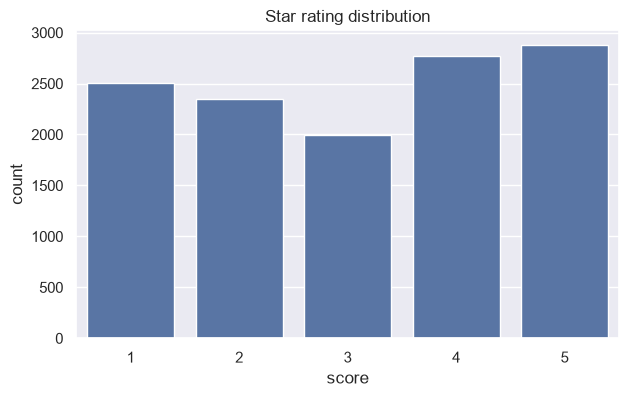

count    12495.000000
mean         3.094198
std          1.457693
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: score, dtype: float64


In [5]:
if 'score' in df.columns:
    plt.figure(figsize=(7,4))
    sns.countplot(x=df['score'].round()).set_title('Star rating distribution')
    plt.show()
    print(df['score'].describe())

## 5. Review-length distribution (words)

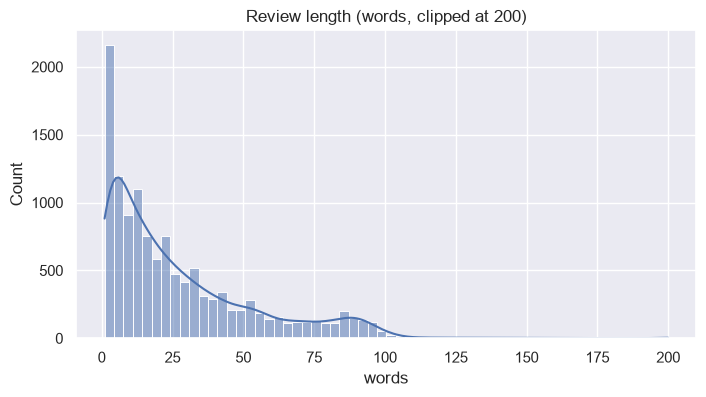

count    12495.000000
mean        27.675710
std         28.381852
min          1.000000
25%          7.000000
50%         18.000000
75%         40.000000
max        723.000000
Name: review, dtype: float64


In [6]:
lengths = df['review'].fillna('').str.split().str.len()
plt.figure(figsize=(8,4))
sns.histplot(lengths.clip(upper=200), bins=60, kde=True)
plt.title('Review length (words, clipped at 200)')
plt.xlabel('words')
plt.show()
print(lengths.describe())

## 6. Word clouds (raw + high vs low rating)

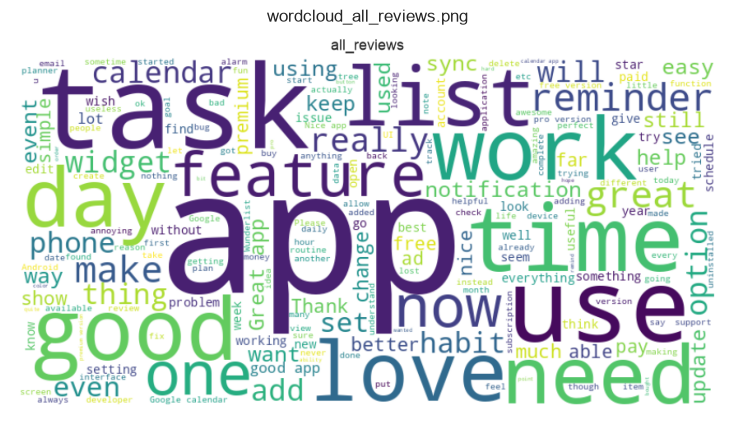

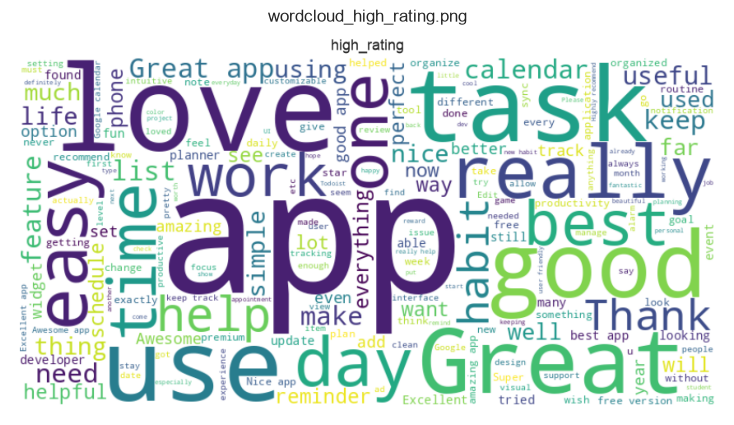

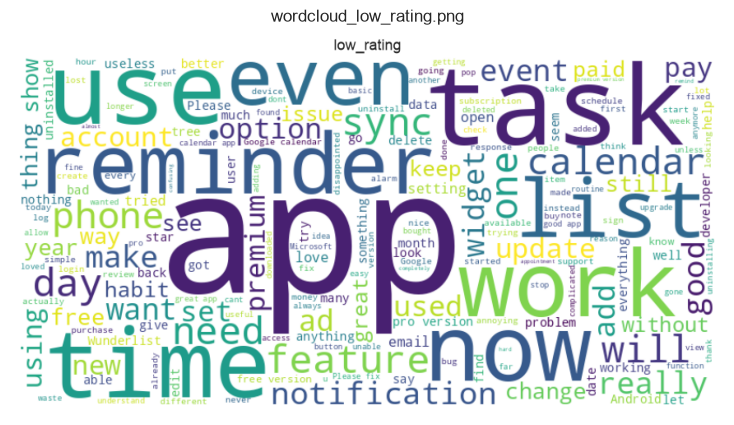

In [7]:
from src.evaluate import wordcloud_images
wordcloud_images(df['review'].dropna(), title='all_reviews')
if 'score' in df.columns:
    wordcloud_images(df[df['score']>=4.5]['review'].dropna(), title='high_rating')
    wordcloud_images(df[df['score']<=2]['review'].dropna(), title='low_rating')
import glob, matplotlib.image as mpimg
for p in sorted(glob.glob(os.path.join(DATA_PROCESSED,'figures','wordcloud_*.png'))):
    plt.figure(figsize=(10,5)); plt.imshow(mpimg.imread(p)); plt.axis('off'); plt.title(p.split('/')[-1]); plt.show()

## 7. Clean & persist
Drop null / duplicate / very short reviews and build `text` + `raw_text`.

In [8]:
from src.preprocess import preprocess_dataframe
clean = preprocess_dataframe(df, review_col='review', min_words=3)
print('kept', len(clean), 'of', len(df), 'reviews')
os.makedirs(DATA_PROCESSED, exist_ok=True)
clean.to_csv(os.path.join(DATA_PROCESSED, 'reviews_clean.csv'), index=False)
clean[['raw_text','text']].head(10)

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/sudowoodo/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


kept 11159 of 12495 reviews


,raw_text,text
0,I cannot open the app anymore,not open app anymore
1,I have been begging for a refund from this app for over a month and nobody i...,begging refund app month nobody replying
2,Very costly for the premium version (approx Indian Rupees 910 per year). Bet...,costly premium version approx indian rupee per year better download premium ...
3,"Used to keep me organized, but all the 2020 UPDATES have made a mess of thin...",used keep organized update made mess thing cudnt leave well enuf alone guess...
4,Dan Birthday Oct 28,dan birthday oct
5,It has changed how I viewed my different lists. Now they are all jumbled tog...,changed viewed different list jumbled together cant find need
6,I'm only looking for a grocery list app but every time I tap away from the a...,im looking grocery list app every time tap away app tap opening see list can...
7,"Reset my free trial, new phone I'd like to see if it's better.",reset free trial new phone id like see better
8,How do to stop monthly payment because i don't use this app anymore,stop monthly payment dont use app anymore
9,I complain about not crashes and it was immediately fixed!Good job!! Now the...,complain not crash immediately fixedgood job crash returned really need fixe...


**Next:** open `02_clustering.ipynb`.